# 평탄 표면 인식 기반 Geometry-aware Depth Refinement
**7팀 | 장준용 / 최원호**

---
## 파이프라인 개요
```
RGB 이미지 (여러 장)
    ↓
[SECTION 0] 환경 설정 & 모델 로드
    ↓
[SECTION 1] 이미지 로드 + EXIF focal length 추출
    ↓
[SECTION 2] Depth Anything V2 → baseline depth map
    ↓
[SECTION 3] SegFormer → 평탄 영역 마스크
    ↓
[SECTION 4] RANSAC+SVD Plane Fitting + 이상치 heat map
    ↓
[SECTION 5] Confidence map 블렌딩 + Guided Filtering
    ↓
[SECTION 6] 3-way 비교 (원본 / Blur / 우리)
    ↓
[SECTION 7] 정량 평가 테이블
    ↓
[SECTION 8] 최종 시각화
```

---
## SECTION 0 | 환경 설정

In [2]:
# [셀 0-1] 라이브러리 설치
!pip install -q transformers torch torchvision pillow matplotlib opencv-python-headless numpy scipy
!pip install -q opencv-contrib-python-headless
!pip install -q segment-anything

import os
if not os.path.exists('sam_vit_b_01ec64.pth'):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    print('SAM 체크포인트 다운로드 완료')
else:
    print('SAM 체크포인트 이미 존재')
print('설치 완료')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 MB 13.2 MB/s eta 0:00:00
SAM 체크포인트 다운로드 완료
설치 완료


In [3]:
# [셀 0-2] Import + 디바이스 설정
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageFile
from pathlib import Path
from scipy.ndimage import gaussian_filter
import warnings
import pandas as pd
from transformers import pipeline
import platform, os

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch      : {torch.__version__}')
print(f'CUDA 사용    : {torch.cuda.is_available()}')
print(f'Device       : {DEVICE}')

PyTorch      : 2.11.0+cu128
CUDA 사용    : True
Device       : cuda


In [4]:
# [셀 0-3] 한글 폰트 설정
system = platform.system()
if system == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif system == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
print('한글 폰트 설정 완료:', plt.rcParams['font.family'])

한글 폰트 설정 완료: ['DejaVu Sans']


---
## SECTION 1 | 이미지 입력
### ⚠️ 여기만 수정하면 됩니다
Colab 왼쪽 파일 탭에 사진을 업로드한 뒤, 파일명을 아래에 입력하세요.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# [셀 1-1] 이미지 경로 설정 (← 이 부분만 수정)
IMAGE_PATHS = [
    # '/content/sample_data/4.jpg',   # 여기에 업로드한 사진 경로 입력
    # '/content/sample_data/104.jpg',
    # '/content/사진3.jpg',  # 더 있으면 추가
    # '/content/sample_data/10.jpg',
    # '/content/sample_data/4.jpg',
    # '/content/sample_data/104.jpg'
    '/content/sample_data/땅콩샌드.jpg'
]

# 존재하는 파일만 필터링
IMAGE_PATHS = [p for p in IMAGE_PATHS if Path(p).exists()]
print(f'로드할 이미지: {len(IMAGE_PATHS)}장')
for p in IMAGE_PATHS:
    print(f'  - {p}')

if len(IMAGE_PATHS) == 0:
    print('\n⚠️ 이미지를 찾을 수 없습니다. 경로를 확인해주세요.')

로드할 이미지: 1장
  - /content/sample_data/땅콩샌드.jpg


In [7]:
# [셀 1-2] EXIF focal length 자동 추출 함수
from PIL.ExifTags import TAGS

def get_focal_length(img_path):
    """
    EXIF에서 focal length 읽기.
    아이폰/갤럭시 모두 지원.
    없으면 None 반환 → 이후 추정값 사용.
    """
    try:
        img = Image.open(img_path)
        exif_data = img._getexif()
        if exif_data is None:
            return None
        for tag_id, value in exif_data.items():
            tag = TAGS.get(tag_id, tag_id)
            if tag == 'FocalLength':
                # IFDRational or tuple
                if hasattr(value, 'numerator'):
                    return float(value.numerator) / float(value.denominator)
                elif isinstance(value, tuple):
                    return float(value[0]) / float(value[1])
                else:
                    return float(value)
    except Exception:
        pass
    return None

def get_fx_fy(img_path, W, H):
    """
    focal length (mm) → 픽셀 단위 fx, fy 변환.
    sensor width 추정 (스마트폰 기준 ~4.8mm).
    EXIF 없으면 max(W,H)*0.7 fallback.
    """
    fl_mm = get_focal_length(img_path)
    if fl_mm is not None:
        # 스마트폰 sensor width 추정: 아이폰14Pro ~4.2mm, 갤S24 ~5.1mm
        # 보수적으로 4.8mm 사용
        sensor_w_mm = 4.8
        fx = fl_mm * W / sensor_w_mm
        fy = fx  # square pixels 가정
        source = f'EXIF ({fl_mm:.1f}mm)'
    else:
        fx = fy = max(W, H) * 0.7
        source = '추정값 (EXIF 없음)'
    return fx, fy, source

# 테스트
if IMAGE_PATHS:
    test_img = Image.open(IMAGE_PATHS[0])
    W_test, H_test = test_img.size
    fx_t, fy_t, src_t = get_fx_fy(IMAGE_PATHS[0], W_test, H_test)
    print(f'첫 번째 이미지: {W_test}x{H_test}')
    print(f'focal length 소스: {src_t}')
    print(f'fx={fx_t:.1f}, fy={fy_t:.1f}')

첫 번째 이미지: 1280x921
focal length 소스: 추정값 (EXIF 없음)
fx=896.0, fy=896.0


### ROI좌표찾는법

---
## SECTION 2 | Depth Anything V2 모델 로드

In [8]:
# [셀 2-1] Depth Anything V2 로드 (기존 코드 그대로)
MODEL_DEPTH = 'depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf'
print(f'모델 로딩: {MODEL_DEPTH}')
depth_pipe = pipeline(
    task='depth-estimation',
    model=MODEL_DEPTH,
    device=0 if DEVICE == 'cuda' else -1
)
print('로딩 완료')

모델 로딩: depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf


config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

로딩 완료


In [9]:
# 선반모드 segforemr
# # [셀 2-2] SegFormer 로드
# MODEL_SEG = 'nvidia/segformer-b5-finetuned-ade-640-640'
# print(f'모델 로딩: {MODEL_SEG}')
# seg_pipe = pipeline(
#     task='image-segmentation',
#     model=MODEL_SEG,
#     device=0 if DEVICE == 'cuda' else -1
# )
# print('로딩 완료')

# PLANE_LABELS = {'wall', 'floor'}

# # 선반 사진 모드 ON/OFF
# # True  → Hough Transform으로 선반 테두리 잡기
# # False → 기존 SegFormer 방식
# SHELF_MODE = False

# # texture threshold (선반 모드일 때는 의미 없음)
# TEXTURE_THRESHOLD = 30.0

# print(f'PLANE_LABELS: {PLANE_LABELS}')
# print(f'SHELF_MODE: {SHELF_MODE}')

In [10]:
# [셀 2-2] SegFormer 로드 + SAM 로드
MODEL_SEG = 'nvidia/segformer-b5-finetuned-ade-640-640'
print(f'모델 로딩: {MODEL_SEG}')
seg_pipe = pipeline(
    task='image-segmentation',
    model=MODEL_SEG,
    device=0 if DEVICE == 'cuda' else -1
)
print('SegFormer 로딩 완료')

# ⚠️ 여기만 수정하면 됩니다
PLANE_LABELS = {'wall', 'floor'}   # 일반 사진용
SHELF_MODE = True                   # 선반 사진: True / 일반 사진: False
TEXTURE_THRESHOLD = 30.0

print(f'PLANE_LABELS: {PLANE_LABELS}')
print(f'SHELF_MODE: {SHELF_MODE}')

# SAM 로드 (SHELF_MODE=True일 때만)
if SHELF_MODE:
    from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
    sam_model = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
    sam_model.to(device=DEVICE)
    mask_generator = SamAutomaticMaskGenerator(
        sam_model,
        points_per_side=32,
        pred_iou_thresh=0.86,
        stability_score_thresh=0.92,
        min_mask_region_area=500
    )
    print('SAM 로딩 완료')
else:
    print('SAM 로드 스킵 (SHELF_MODE=False)')

모델 로딩: nvidia/segformer-b5-finetuned-ade-640-640


config.json:   0%|          | 0.00/6.89k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/339M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/339M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

SegFormer 로딩 완료
PLANE_LABELS: {'floor', 'wall'}
SHELF_MODE: True
SAM 로딩 완료


In [11]:
# # [셀 2-2] SegFormer 로드 (b5 640×640 업그레이드)
# MODEL_SEG = 'nvidia/segformer-b5-finetuned-ade-640-640'  # b0 → b5
# print(f'모델 로딩: {MODEL_SEG}')
# seg_pipe = pipeline(
#     task='image-segmentation',
#     model=MODEL_SEG,
#     device=0 if DEVICE == 'cuda' else -1
# )
# print('로딩 완료')

# # ceiling 제거, wall/floor만 사용

# PLANE_LABELS = {
#     "shelf",
#     "cabinet",
#     "bookcase",
#     "wall",
#     "box"
# }

# # PLANE_LABELS = {
# #     "wall",
# #     "floor",
# #     # "ceiling",
# #     # "road",
# #     # "sidewalk",
# #     # "earth",
# #     # "ground",
# #     "cabinet",
# #     # "door",
# #     # "countertop",
# #     # "sink",
# #     # "box",
# #     # "mirror"

# # }

# print(f'PLANE_LABELS: {PLANE_LABELS}')

---
## SECTION 3 | 핵심 알고리즘 함수 정의

In [12]:
# [셀 3-1] RANSAC + SVD Plane Fitting
def fit_plane_ransac_svd(points_3d, n_iters=300, threshold=0.05):
    """RANSAC으로 inlier 찾고 SVD로 refine된 평면 normal/d 반환."""
    N = len(points_3d)
    if N < 10:
        return None
    best_n, best_mask = 0, None
    for _ in range(n_iters):
        idx = np.random.choice(N, 3, replace=False)
        p1, p2, p3 = points_3d[idx]
        normal = np.cross(p2 - p1, p3 - p1)
        nrm = np.linalg.norm(normal)
        if nrm < 1e-6:
            continue
        normal = normal / nrm
        d = np.dot(normal, p1)
        dists = np.abs(points_3d @ normal - d)
        n_in = (dists < threshold).sum()
        if n_in > best_n:
            best_n = n_in
            best_mask = dists < threshold
    if best_mask is None or best_mask.sum() < 10:
        return None
    inliers = points_3d[best_mask]
    centroid = inliers.mean(0)
    _, _, Vt = np.linalg.svd(inliers - centroid, full_matrices=False)
    normal = Vt[-1]
    d = np.dot(normal, centroid)
    return normal, d, best_mask.sum() / N


def refine_depth_for_region(depth, mask, fx=525.0, fy=525.0,
                             threshold=0.08):
    H, W = depth.shape
    cx, cy = W / 2.0, H / 2.0
    ys, xs = np.where(mask)
    if len(ys) < 30:
        return depth.copy(), None, None

    zs = depth[ys, xs]
    Xs = (xs - cx) * zs / fx
    Ys = (ys - cy) * zs / fy
    points = np.stack([Xs, Ys, zs], axis=1)

    res = fit_plane_ransac_svd(points, threshold=threshold)
    if res is None:
        return depth.copy(), None, None
    normal, d, ratio = res
    nx, ny, nz = normal

    refined = depth.copy()
    denom = nx * (xs - cx) / fx + ny * (ys - cy) / fy + nz
    valid = np.abs(denom) > 1e-3
    new_z = np.zeros_like(zs)
    new_z[valid] = d / denom[valid]

    # ── sanity check: 기존 0.1m 고정 → 동적 허용치 ──────
    z_mean    = float(zs.mean())
    max_delta = max(z_mean * 0.3, 0.5)  # depth 평균의 30% 또는 최소 0.5m
    delta     = np.abs(new_z - zs)

    sanity = (
        valid
        & (new_z > 0.05)
        & (new_z < 50.0)
        & (delta < max_delta)
    )

    refined[ys[sanity], xs[sanity]] = new_z[sanity]

    residual_map = np.zeros((H, W), dtype=np.float32)
    residual_map[ys, xs] = np.abs(zs - new_z)

    print(f'    sanity 통과: {sanity.sum():,}/{len(ys):,}픽셀 '
          f'({sanity.sum()/len(ys)*100:.1f}%) '
          f'max_delta={max_delta:.3f}m')

    return refined, (normal, d, ratio, sanity.sum()), residual_map


print('함수 정의 완료')

함수 정의 완료


---
## SECTION 4 | 전체 파이프라인 실행 (이미지 루프)

In [23]:
# [셀 4-1] ROI 직접 지정 기반 파이프라인
from PIL import ImageOps
from scipy.ndimage import gaussian_filter
from pathlib import Path

# ======================================================
# ⚠️ 선반 테두리 ROI 직접 지정
# 원본 이미지 크기 기준으로 입력
# ======================================================
SHELF_ROIS = {
    '땅콩샌드.jpg': [
         (  0,  24,  20, 1265, 'shelf_H_top_outer'),
        (298, 346,  20, 1265, 'shelf_H_top'),
        (587, 636,  20, 1265, 'shelf_H_mid'),
        (876, 921,  20, 1265, 'shelf_H_bot'),
        (  0, 960,   0,  28,  'pillar_left'),
        (  0, 960, 532, 572,  'pillar_center'),
        (  0, 960,1255,1280,  'pillar_right'),
    ],
    # 다른 이미지 추가 시:
    # '선반2.jpg': [...],
}

# True  → 모든 ROI 합쳐서 단일 RANSAC (테두리 전체 균일한 색)
# False → ROI 각각 따로 RANSAC
MERGE_ALL_ROIS = True


def roi_to_masks(img_name, H, W):
    if img_name not in SHELF_ROIS:
        print(f'  ⚠️ {img_name} ROI 없음')
        return []
    masks = []
    for (y0, y1, x0, x1, label) in SHELF_ROIS[img_name]:
        m = np.zeros((H, W), dtype=bool)
        m[max(0, y0):min(H, y1),
          max(0, x0):min(W, x1)] = True
        if m.sum() > 30:
            masks.append((label, m))
            print(f'  + {label}: {m.sum():,}픽셀  '
                  f'(y={y0}~{y1}, x={x0}~{x1})')
    return masks


# ======================================================
# 메인 파이프라인
# ======================================================
all_results = []

for img_path in IMAGE_PATHS:
    print(f'\n{"="*60}')
    print(f'처리 중: {img_path}')
    print('='*60)

    # ── 1. 이미지 로드 (리사이즈 없음) ────────────────────
    img = Image.open(img_path).convert('RGB')
    img = ImageOps.exif_transpose(img)
    W_img, H_img = img.size
    fx, fy, fl_src = get_fx_fy(img_path, W_img, H_img)
    print(f'이미지: {W_img}x{H_img}, fx={fx:.0f}, {fl_src}')

    # ── 2. Depth Anything V2 ───────────────────────────────
    result        = depth_pipe(img)
    depth_map_raw = np.array(result['predicted_depth'])
    depth_resized = (cv2.resize(
                         depth_map_raw.astype(np.float32),
                         (W_img, H_img),
                         interpolation=cv2.INTER_LINEAR)
                     if depth_map_raw.shape != (H_img, W_img)
                     else depth_map_raw.astype(np.float32))
    print(f'Depth: {depth_resized.min():.2f}~{depth_resized.max():.2f}m')

    # ── 3. ROI 마스크 생성 ─────────────────────────────────
    img_np    = np.array(img)
    img_name  = Path(img_path).name
    roi_masks = roi_to_masks(img_name, H_img, W_img)

    plane_mask      = np.zeros((H_img, W_img), dtype=bool)
    plane_per_label = []

    if MERGE_ALL_ROIS and len(roi_masks) > 0:
        merged = np.zeros((H_img, W_img), dtype=bool)
        for _, m in roi_masks:
            merged |= m
            plane_mask |= m
        plane_per_label = [('shelf_all_merged', merged)]
        print(f'  [MERGE 모드] {len(roi_masks)}개 ROI → 1개 통합')
        print(f'  합친 마스크: {merged.sum():,}픽셀')
    else:
        for label, m in roi_masks:
            plane_mask |= m
            plane_per_label.append((label, m))

    print(f'평면 픽셀: {plane_mask.sum():,} ({plane_mask.mean()*100:.1f}%)')

    # ── 4. RANSAC Plane Fitting ────────────────────────────
    refined_depth      = depth_resized.copy()
    total_residual_map = np.zeros((H_img, W_img), dtype=np.float32)
    segment_stats      = []

    for label, m in plane_per_label:
        d_mean = float(depth_resized[m].mean())
        d_std  = float(depth_resized[m].std())
        print(f'\n  [RANSAC] {label}: '
              f'depth={d_mean:.3f}m (std={d_std:.4f})')

        var_b_orig = depth_resized[m].var()

        refined_depth, info, residual_map = refine_depth_for_region(
            refined_depth, m, fx=fx, fy=fy, threshold=0.05)

        if info is None:
            print(f'    fit 실패')
            continue

        nrm, dd, ratio, n_corr = info
        if residual_map is not None:
            total_residual_map += residual_map

        std_b    = float(depth_resized[m].std())
        std_a    = float(refined_depth[m].std())
        var_b    = float(depth_resized[m].var())
        var_a    = float(refined_depth[m].var())
        flatness = float(residual_map[m].mean()) if residual_map is not None else 0
        improvement = (1 - var_a/var_b)*100 if var_b > 0 else 0

        if var_a > var_b_orig * 2.0:
            print(f'    [롤백] 분산 2배 초과 → 원본 복구')
            refined_depth[m] = depth_resized[m]
            improvement = 0.0
            std_a = std_b
        else:
            print(f'    분산감소: {improvement:.1f}%  '
                  f'inlier: {ratio*100:.0f}%  '
                  f'std: {std_b:.4f}→{std_a:.4f}')

        segment_stats.append({
            '이미지':         Path(img_path).name,
            '영역':           label,
            'std_before':     round(std_b, 4),
            'std_after':      round(std_a, 4),
            'std_감소율(%)':    round((1-std_a/std_b)*100, 1)
                               if std_b > 0 else 0,
            '분산_감소율(%)':   round(improvement, 1),
            'flatness_score': round(flatness, 4),
            'inlier(%)':      round(ratio*100, 1),
            '보정픽셀':        int(n_corr),
        })

    # ── 5. NaN 처리 ────────────────────────────────────────
    refined_depth = np.where(
        np.isnan(refined_depth), depth_resized, refined_depth)
    refined_depth = np.nan_to_num(
        refined_depth, nan=0.0).astype(np.float32)

    # ── 6. Guided Filtering ────────────────────────────────
    rgb_guide = np.array(img)
    try:
        diff          = refined_depth - depth_resized
        diff_smoothed = cv2.ximgproc.guidedFilter(
            guide=rgb_guide,
            src=diff.astype(np.float32),
            radius=8, eps=0.01)
        soft_mask     = cv2.ximgproc.guidedFilter(
            guide=rgb_guide,
            src=plane_mask.astype(np.float32),
            radius=8, eps=0.01)
        soft_mask     = np.clip(soft_mask, 0.0, 1.0)
        final_depth   = depth_resized + soft_mask * diff_smoothed
        final_depth[~plane_mask] = depth_resized[~plane_mask]
        abnormal = (final_depth <= 0) | np.isnan(final_depth)
        final_depth[abnormal] = depth_resized[abnormal]
        blend_method  = 'Guided Filter (diff)'
    except Exception:
        soft_mask   = np.clip(
            gaussian_filter(plane_mask.astype(np.float32), sigma=6.0),
            0.0, 1.0)
        final_depth = (soft_mask * refined_depth
                       + (1-soft_mask) * depth_resized)
        final_depth[~plane_mask] = depth_resized[~plane_mask]
        blend_method = 'Gaussian (fallback)'
    print(f'\n블렌딩: {blend_method}')

    # ── 7. Edge Preservation ───────────────────────────────
    gray_edge  = cv2.cvtColor(rgb_guide, cv2.COLOR_RGB2GRAY)
    edges_eval = cv2.Canny(gray_edge, 50, 150).astype(bool)
    if edges_eval.sum() > 0:
        ec_b = np.abs(np.gradient(depth_resized)[0][edges_eval]).mean()
        ec_a = np.abs(np.gradient(final_depth)[0][edges_eval]).mean()
        edge_preserve = round(float(ec_a/(ec_b+1e-6)), 3)
    else:
        edge_preserve = 1.0

    blur_depth = cv2.GaussianBlur(depth_resized, (15, 15), 0)

    all_results.append({
        'img_path':      img_path,
        'img':           img,
        'depth_resized': depth_resized,
        'refined_depth': refined_depth,
        'final_depth':   final_depth,
        'blur_depth':    blur_depth,
        'plane_mask':    plane_mask,
        'residual_map':  total_residual_map,
        'segment_stats': segment_stats,
        'blend_method':  blend_method,
        'edge_preserve': edge_preserve,
        'fx':            fx,
        'fy':            fy,
        'fl_src':        fl_src,
    })

print(f'\n전체 처리 완료: {len(all_results)}장')


처리 중: /content/sample_data/땅콩샌드.jpg
이미지: 1280x921, fx=896, 추정값 (EXIF 없음)
Depth: 1.02~1.69m
  + shelf_H_top_outer: 29,880픽셀  (y=0~24, x=20~1265)
  + shelf_H_top: 59,760픽셀  (y=298~346, x=20~1265)
  + shelf_H_mid: 61,005픽셀  (y=587~636, x=20~1265)
  + shelf_H_bot: 56,025픽셀  (y=876~921, x=20~1265)
  + pillar_left: 25,788픽셀  (y=0~960, x=0~28)
  + pillar_center: 36,840픽셀  (y=0~960, x=532~572)
  + pillar_right: 23,025픽셀  (y=0~960, x=1255~1280)
  [MERGE 모드] 7개 ROI → 1개 통합
  합친 마스크: 282,695픽셀
평면 픽셀: 282,695 (24.0%)

  [RANSAC] shelf_all_merged: depth=1.206m (std=0.0611)
    sanity 통과: 282,695/282,695픽셀 (100.0%) max_delta=0.500m
    분산감소: 63.7%  inlier: 84%  std: 0.0611→0.0368

블렌딩: Guided Filter (diff)

전체 처리 완료: 1장


---
## SECTION 5 | 이상치 Heat Map 시각화

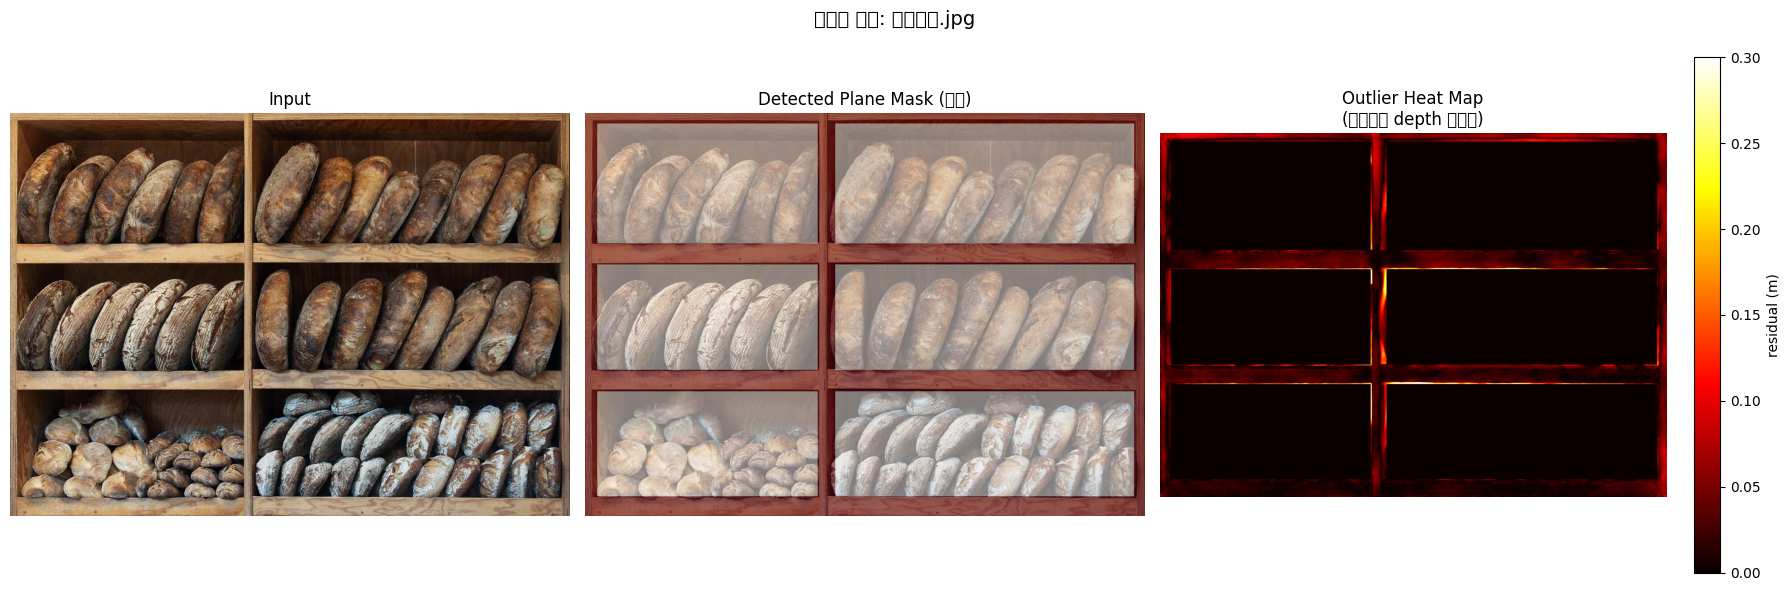

In [24]:
# [셀 5-1] 이상치 Heat Map (어디가 outlier였는지)
for r in all_results:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(f'이상치 분석: {Path(r["img_path"]).name}', fontsize=14)

    # 원본 이미지
    axes[0].imshow(r['img'])
    axes[0].set_title('Input')
    axes[0].axis('off')

    # 평면 마스크
    axes[1].imshow(r['img'])
    axes[1].imshow(r['plane_mask'], alpha=0.5, cmap='Reds')
    axes[1].set_title('Detected Plane Mask (빨강)')
    axes[1].axis('off')

    # 이상치 heat map
    im = axes[2].imshow(r['residual_map'], cmap='hot', vmin=0, vmax=0.3)
    axes[2].set_title('Outlier Heat Map\n(밝을수록 depth 이상치)')
    axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046, label='residual (m)')

    plt.tight_layout()
    plt.show()

---
## SECTION 6 | 3-way 비교 (원본 / Blur / 우리 방법)

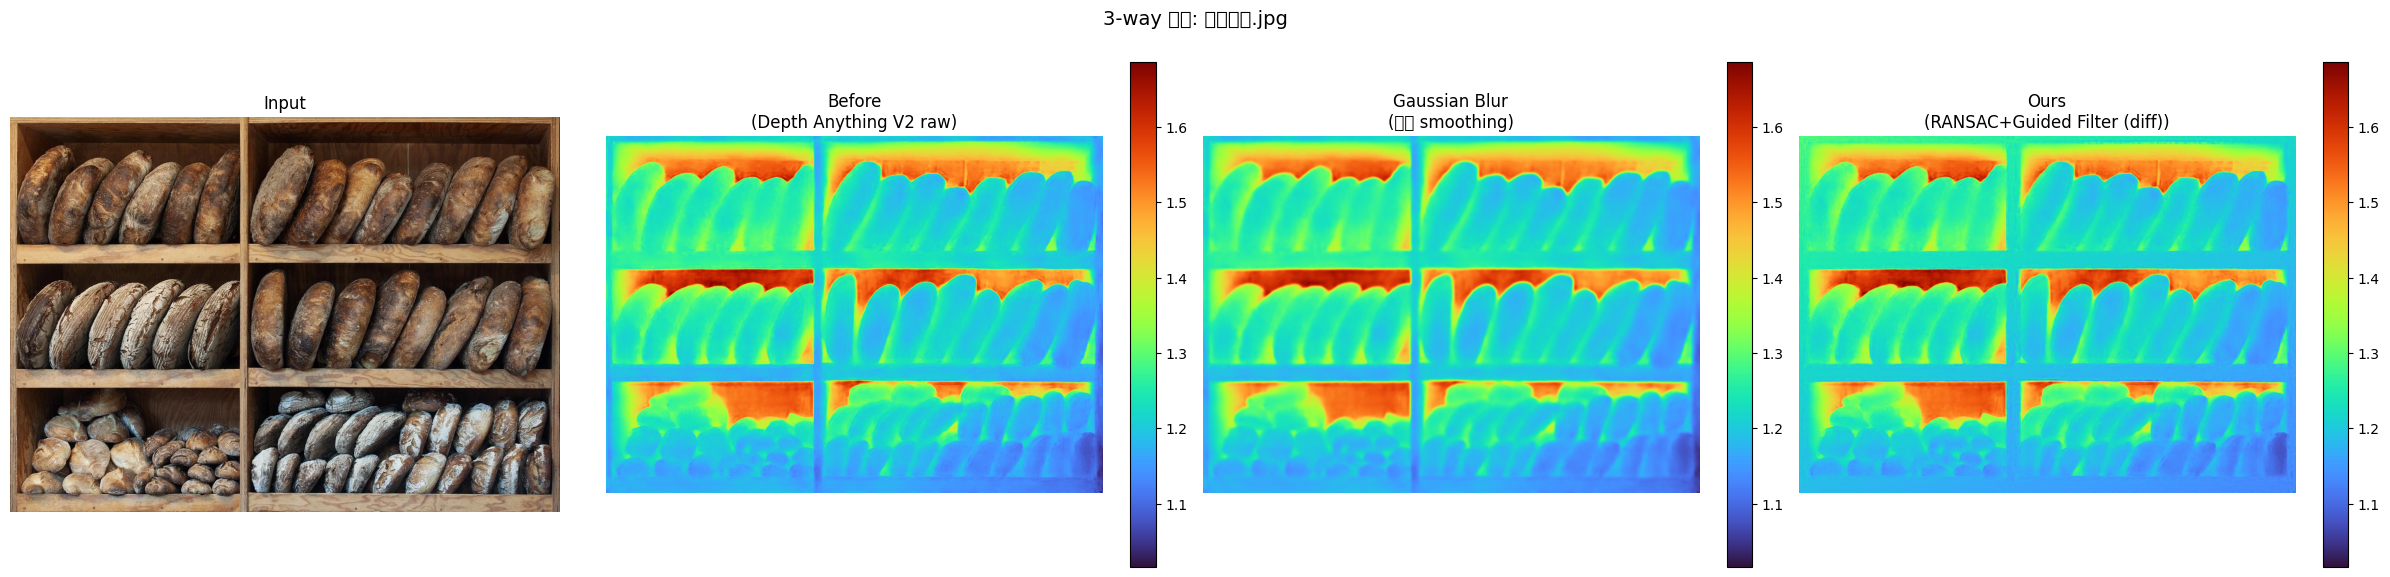

In [25]:
# [셀 6-1] 3가지 방법 나란히 비교
# "왜 blur가 아니라 plane fitting이어야 하는가"를 눈으로 보여줌
for r in all_results:
    vmin = float(r['depth_resized'].min())
    vmax = float(r['depth_resized'].max())

    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.suptitle(f'3-way 비교: {Path(r["img_path"]).name}', fontsize=14)

    # 원본 이미지
    axes[0].imshow(r['img'])
    axes[0].set_title('Input')
    axes[0].axis('off')

    # Depth Anything V2 단독 (Before)
    im1 = axes[1].imshow(r['depth_resized'], cmap='turbo', vmin=vmin, vmax=vmax)
    axes[1].set_title('Before\n(Depth Anything V2 raw)')
    axes[1].axis('off')
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    # Gaussian Blur 전체 (비교용)
    im2 = axes[2].imshow(r['blur_depth'], cmap='turbo', vmin=vmin, vmax=vmax)
    axes[2].set_title('Gaussian Blur\n(단순 smoothing)')
    axes[2].axis('off')
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    # 우리 방법
    im3 = axes[3].imshow(r['final_depth'], cmap='turbo', vmin=vmin, vmax=vmax)
    axes[3].set_title(f'Ours\n(RANSAC+{r["blend_method"]})')
    axes[3].axis('off')
    plt.colorbar(im3, ax=axes[3], fraction=0.046)

    plt.tight_layout()
    plt.savefig(f'/content/comparison_{Path(r["img_path"]).stem}.png',
                dpi=120, bbox_inches='tight')
    plt.show()

---
## SECTION 7 | 정량 평가 테이블

In [26]:
# [셀 7-1] 정량 평가 결과 테이블
all_stats = []
for r in all_results:
    for s in r['segment_stats']:
        s['edge_preserve'] = r['edge_preserve']
        all_stats.append(s)

if all_stats:
    df = pd.DataFrame(all_stats)
    # 컬럼 순서 정리
    cols = ['이미지', '영역', 'std_before', 'std_after', 'std_감소율(%)',
            '분산_감소율(%)', 'flatness_score', 'inlier(%)', '보정픽셀', 'edge_preserve']
    df = df[cols]
    print('=' * 80)
    print('정량 평가 결과')
    print('=' * 80)
    print(df.to_string(index=False))
    print()
    print('─' * 80)
    print(f'평균 std 감소율  : {df["std_감소율(%)"].mean():.1f}%')
    print(f'평균 분산 감소율 : {df["분산_감소율(%)"].mean():.1f}%')
    print(f'평균 inlier 비율 : {df["inlier(%)"].mean():.1f}%')
    print(f'평균 edge preserve (1.0=완전보존): {df["edge_preserve"].mean():.3f}')
    print()
    print('※ std/분산 감소율 높을수록 depth noise 감소')
    print('※ flatness_score 낮을수록 평면에 가까워진 것')
    print('※ edge_preserve 1.0에 가까울수록 경계 보존됨')
else:
    print('처리된 결과가 없습니다.')

정량 평가 결과
     이미지               영역  std_before  std_after  std_감소율(%)  분산_감소율(%)  flatness_score  inlier(%)   보정픽셀  edge_preserve
땅콩샌드.jpg shelf_all_merged      0.0611     0.0368        39.7       63.7          0.0325       83.6 282695          1.009

────────────────────────────────────────────────────────────────────────────────
평균 std 감소율  : 39.7%
평균 분산 감소율 : 63.7%
평균 inlier 비율 : 83.6%
평균 edge preserve (1.0=완전보존): 1.009

※ std/분산 감소율 높을수록 depth noise 감소
※ flatness_score 낮을수록 평면에 가까워진 것
※ edge_preserve 1.0에 가까울수록 경계 보존됨


---
## SECTION 8 | 최종 Before/After 시각화

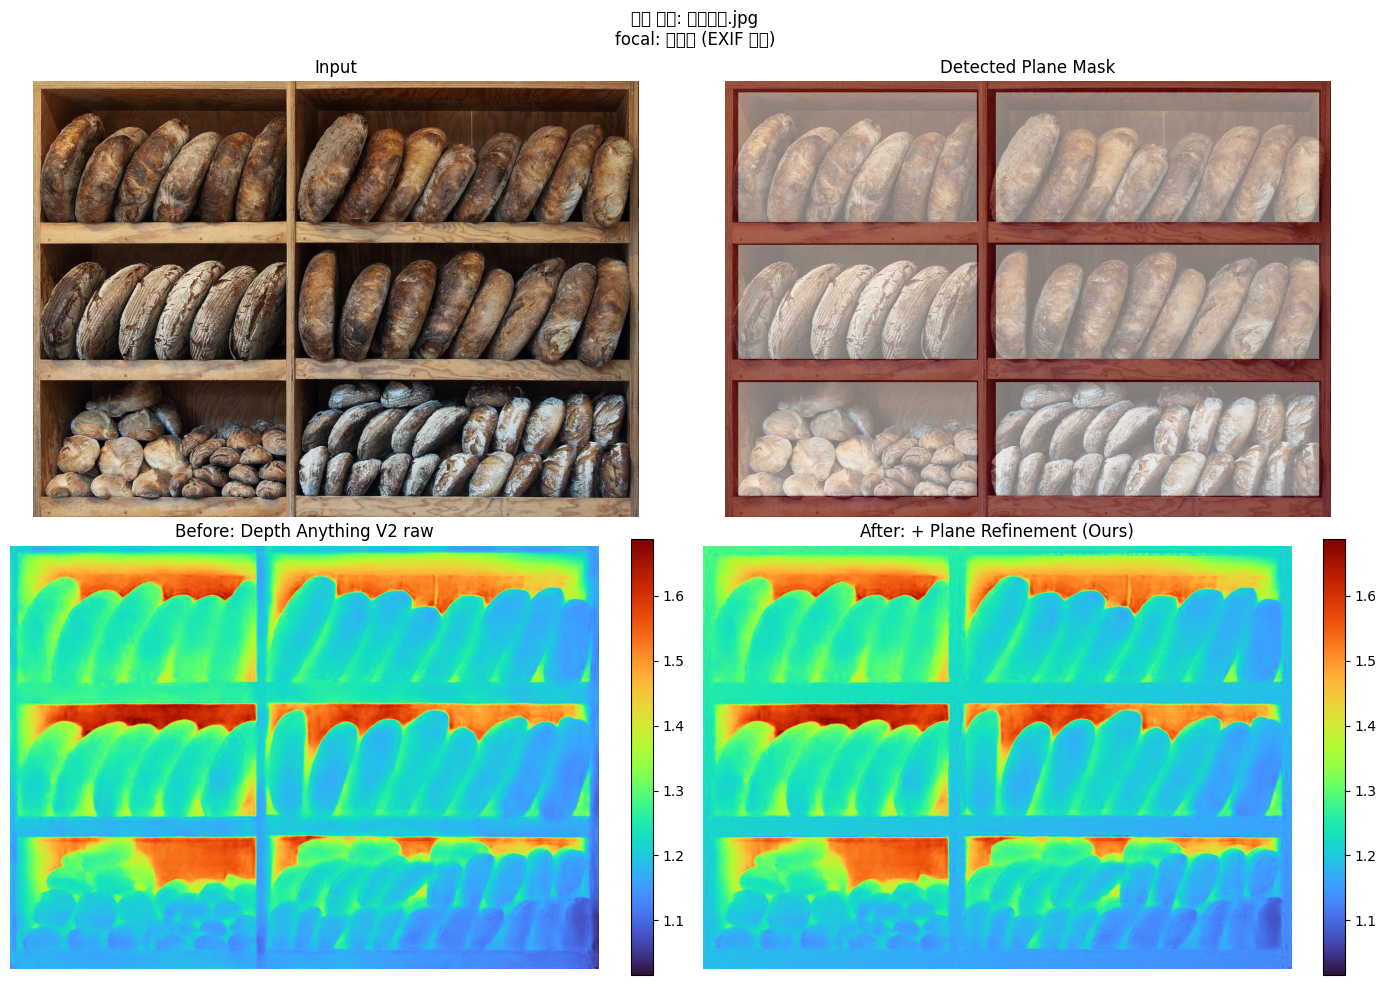

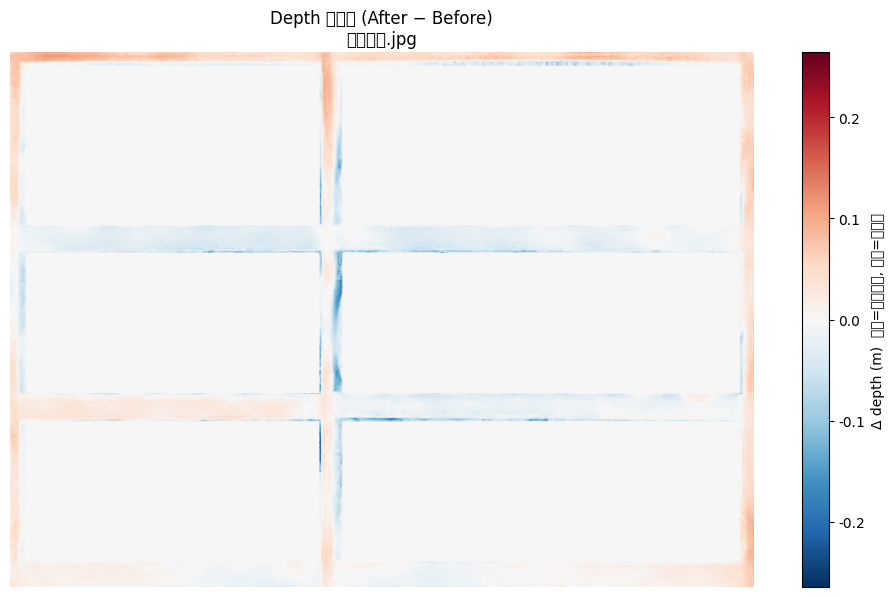

In [27]:
# [셀 8-1] Before / After / Diff map (이미지별)
for r in all_results:
    vmin = float(r['depth_resized'].min())
    vmax = float(r['depth_resized'].max())

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'최종 결과: {Path(r["img_path"]).name}\n'
                 f'focal: {r["fl_src"]}', fontsize=12)

    # Input
    axes[0,0].imshow(r['img'])
    axes[0,0].set_title('Input')
    axes[0,0].axis('off')

    # Plane Mask
    axes[0,1].imshow(r['img'])
    axes[0,1].imshow(r['plane_mask'], alpha=0.5, cmap='Reds')
    axes[0,1].set_title('Detected Plane Mask')
    axes[0,1].axis('off')

    # Before
    im0 = axes[1,0].imshow(r['depth_resized'], cmap='turbo', vmin=vmin, vmax=vmax)
    axes[1,0].set_title('Before: Depth Anything V2 raw')
    axes[1,0].axis('off')
    plt.colorbar(im0, ax=axes[1,0], fraction=0.046)

    # After
    im1 = axes[1,1].imshow(r['final_depth'], cmap='turbo', vmin=vmin, vmax=vmax)
    axes[1,1].set_title(f'After: + Plane Refinement (Ours)')
    axes[1,1].axis('off')
    plt.colorbar(im1, ax=axes[1,1], fraction=0.046)

    plt.tight_layout()
    plt.savefig(f'/content/result_{Path(r["img_path"]).stem}.png',
                dpi=120, bbox_inches='tight')
    plt.show()

    # Diff map
    diff = r['final_depth'] - r['depth_resized']
    mx = max(abs(diff.min()), abs(diff.max()), 0.01)
    plt.figure(figsize=(10, 6))
    plt.imshow(diff, cmap='RdBu_r', vmin=-mx, vmax=mx)
    plt.colorbar(label='Δ depth (m)  음수=가까워짐, 양수=멀어짐')
    plt.title(f'Depth 변화량 (After − Before)\n{Path(r["img_path"]).name}')
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(f'/content/diff_{Path(r["img_path"]).stem}.png',
                dpi=120, bbox_inches='tight')
    plt.show()

In [28]:
# [셀 8-2] 전체 이미지 Summary Grid (여러 장일 때 한눈에)
n = len(all_results)
if n > 1:
    fig, axes = plt.subplots(n, 3, figsize=(18, 6*n))
    if n == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle('전체 이미지 요약', fontsize=16)

    for i, r in enumerate(all_results):
        vmin = float(r['depth_resized'].min())
        vmax = float(r['depth_resized'].max())
        name = Path(r['img_path']).name

        axes[i,0].imshow(r['img'])
        axes[i,0].set_title(f'{name}\nInput')
        axes[i,0].axis('off')

        axes[i,1].imshow(r['depth_resized'], cmap='turbo', vmin=vmin, vmax=vmax)
        axes[i,1].set_title('Before')
        axes[i,1].axis('off')

        axes[i,2].imshow(r['final_depth'], cmap='turbo', vmin=vmin, vmax=vmax)
        # 정량 요약 표시
        stats = r['segment_stats']
        if stats:
            avg_std_drop = np.mean([s['std_감소율(%)'] for s in stats])
            axes[i,2].set_title(f'After (Ours)\nstd 평균 감소: {avg_std_drop:.1f}%')
        else:
            axes[i,2].set_title('After (Ours)')
        axes[i,2].axis('off')

    plt.tight_layout()
    plt.savefig('/content/summary_all.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('summary_all.png 저장 완료')
else:
    print('이미지가 1장이라 summary grid 생략')

이미지가 1장이라 summary grid 생략


### 이미지저장코드

In [29]:
# [셀 8-3] 저장된 파일 목록 확인
import glob
saved = glob.glob('/content/*.png')
print(f'저장된 결과 파일 ({len(saved)}개):')
for f in sorted(saved):
    print(f'  {f}')
print('\n완료!')

저장된 결과 파일 (4개):
  /content/comparison_땅콩샌드.png
  /content/diff_땅콩샌드.png
  /content/metrics_chart.png
  /content/result_땅콩샌드.png

완료!


평가지표추가

In [20]:
# [셀 7-2] 성공함 버전 평가지표 함수 정의

def compute_gradient_smoothness(depth_map, mask):
    """셀 내부 depth gradient 크기 평균. 낮을수록 평탄."""
    gx = cv2.Sobel(depth_map.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(depth_map.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    grad_mag = np.sqrt(gx**2 + gy**2)
    return float(grad_mag[mask].mean()) if mask.sum() > 0 else 0.0


def compute_plane_rmse(depth_map, mask, fx, fy):
    """RANSAC plane fitting 후 residual RMSE. 낮을수록 실제 평면에 가까움."""
    H, W = depth_map.shape
    cx, cy = W / 2.0, H / 2.0
    ys, xs = np.where(mask)
    if len(ys) < 20:
        return float('nan'), float('nan')
    zs = depth_map[ys, xs].astype(np.float64)
    Xs = (xs - cx) * zs / fx
    Ys = (ys - cy) * zs / fy
    points = np.stack([Xs, Ys, zs], axis=1)
    res = fit_plane_ransac_svd(points, threshold=0.08)
    if res is None:
        return float('nan'), float('nan')
    normal, d, inlier_ratio = res
    dists = np.abs(points @ normal - d)
    rmse  = float(np.sqrt((dists**2).mean()))
    return rmse, inlier_ratio


def compute_row_consistency(depth_map, masks_by_row):
    """같은 행 셀들의 depth 평균값 편차. 낮을수록 행 일관성 높음."""
    row_stds = []
    for row_idx, row_masks in masks_by_row.items():
        means = [float(depth_map[m].mean()) for m in row_masks if m.sum() > 0]
        if len(means) >= 2:
            row_stds.append(float(np.std(means)))
    return float(np.mean(row_stds)) if row_stds else float('nan')


print('평가지표 함수 정의 완료')

평가지표 함수 정의 완료


In [21]:
# [셀 7-3] 성공함 버전 평가지표 계산

import pandas as pd

all_stats_v4   = []
all_row_cons_v4 = []

for r in all_results:
    img_name     = Path(r['img_path']).name
    depth_v2     = r['depth_resized']
    depth_v4     = r['final_depth']
    fx           = r['fx']
    fy           = r['fy']
    plane_mask   = r['plane_mask']

    # all_results에서 ROI 마스크 목록 복원
    # plane_per_label은 파이프라인 루프 안에서만 존재하므로
    # segment_stats에서 영역명 가져와서 마스크 재생성
    shelf_masks = []
    img_np = np.array(r['img'])
    H_img, W_img = depth_v2.shape

    img_name_key = Path(r['img_path']).name
    if img_name_key in SHELF_ROIS:
        for (y0, y1, x0, x1, label) in SHELF_ROIS[img_name_key]:
            m = np.zeros((H_img, W_img), dtype=bool)
            m[max(0,y0):min(H_img,y1),
              max(0,x0):min(W_img,x1)] = True
            if m.sum() > 30:
                shelf_masks.append((label, m))
    else:
        # MERGE_ALL_ROIS=True인 경우 전체 plane_mask 하나로
        shelf_masks = [('shelf_all_merged', plane_mask)]

    rows_data    = []
    masks_by_row_v2 = {}
    masks_by_row_v4 = {}

    for idx, (label, m) in enumerate(shelf_masks):
        var_v2  = float(depth_v2[m].var())
        var_v4  = float(depth_v4[m].var())
        std_v2  = float(depth_v2[m].std())
        std_v4  = float(depth_v4[m].std())
        var_red = (1 - var_v4 / var_v2) * 100 if var_v2 > 0 else 0.0

        rmse_v2, inlier_v2 = compute_plane_rmse(depth_v2, m, fx, fy)
        rmse_v4, inlier_v4 = compute_plane_rmse(depth_v4, m, fx, fy)
        smooth_v2 = compute_gradient_smoothness(depth_v2, m)
        smooth_v4 = compute_gradient_smoothness(depth_v4, m)

        rows_data.append({
            'image':           img_name,
            'cell':            label,
            'std_v2':          round(std_v2, 4),
            'std_v4':          round(std_v4, 4),
            'var_reduction_%': round(var_red, 1),
            'rmse_v2':         round(rmse_v2, 4) if not np.isnan(rmse_v2) else None,
            'rmse_v4':         round(rmse_v4, 4) if not np.isnan(rmse_v4) else None,
            'inlier_v2_%':    round(inlier_v2*100, 1) if not np.isnan(inlier_v2) else None,
            'inlier_v4_%':    round(inlier_v4*100, 1) if not np.isnan(inlier_v4) else None,
            'grad_smooth_v2':  round(smooth_v2, 4),
            'grad_smooth_v4':  round(smooth_v4, 4),
        })

        # 행 일관성 그룹화 (label에서 row 인덱스 추출)
        row_idx = idx  # 기본값
        if 'top' in label:   row_idx = 0
        elif 'mid' in label: row_idx = 1
        elif 'bot' in label: row_idx = 2

        masks_by_row_v2.setdefault(row_idx, []).append(m)
        masks_by_row_v4.setdefault(row_idx, []).append(m)

    df_img = pd.DataFrame(rows_data)
    all_stats_v4.append(df_img)

    row_cons_v2 = compute_row_consistency(depth_v2, masks_by_row_v2)
    row_cons_v4 = compute_row_consistency(depth_v4, masks_by_row_v4)
    all_row_cons_v4.append({
        'image':              img_name,
        'row_consistency_v2': round(row_cons_v2, 4) if not np.isnan(row_cons_v2) else None,
        'row_consistency_v4': round(row_cons_v4, 4) if not np.isnan(row_cons_v4) else None,
    })

# 전체 출력
if all_stats_v4:
    df_all = pd.concat(all_stats_v4, ignore_index=True)

    print('\n' + '='*80)
    print('📊 상세 평가지표 (v2 baseline vs v4 refined)')
    print('='*80)
    print(df_all.to_string(index=False))

    print('\n' + '-'*80)
    print(f'평균 분산 감소율    : {df_all["var_reduction_%"].mean():.1f}%')
    print(f'평균 RMSE (v2)      : {df_all["rmse_v2"].mean():.4f} m')
    print(f'평균 RMSE (v4)      : {df_all["rmse_v4"].mean():.4f} m')
    print(f'평균 Grad Smooth (v2): {df_all["grad_smooth_v2"].mean():.4f}')
    print(f'평균 Grad Smooth (v4): {df_all["grad_smooth_v4"].mean():.4f}')

    print('\n행 일관성 (Row Consistency, 낮을수록 좋음):')
    df_rc = pd.DataFrame(all_row_cons_v4)
    print(df_rc.to_string(index=False))

    print('\n※ var_reduction_%  : 높을수록 depth noise 감소')
    print('※ rmse             : 낮을수록 실제 평면에 가까움')
    print('※ grad_smooth      : 낮을수록 depth가 부드러운 평면')
    print('※ row_consistency  : 낮을수록 같은 행 선반들이 균일한 depth')


📊 상세 평가지표 (v2 baseline vs v4 refined)
   image          cell  std_v2  std_v4  var_reduction_%  rmse_v2  rmse_v4  inlier_v2_%  inlier_v4_%  grad_smooth_v2  grad_smooth_v4
땅콩샌드.jpg   shelf_H_top  0.0454  0.0372             32.9   0.0179   0.0185        100.0        100.0          0.0500          0.0572
땅콩샌드.jpg   shelf_H_mid  0.0540  0.0437             34.5   0.0185   0.0180        100.0        100.0          0.0667          0.0739
땅콩샌드.jpg   shelf_H_bot  0.0231  0.0166             48.3   0.0117   0.0054        100.0        100.0          0.0156          0.0142
땅콩샌드.jpg   pillar_left  0.0436  0.0356             33.4   0.0080   0.0086        100.0        100.0          0.0394          0.0350
땅콩샌드.jpg pillar_center  0.0692  0.0457             56.5   0.0158   0.0157        100.0        100.0          0.0688          0.0640
땅콩샌드.jpg  pillar_right  0.0447  0.0335             44.0   0.0065   0.0076        100.0        100.0          0.0374          0.0324

------------------------------------

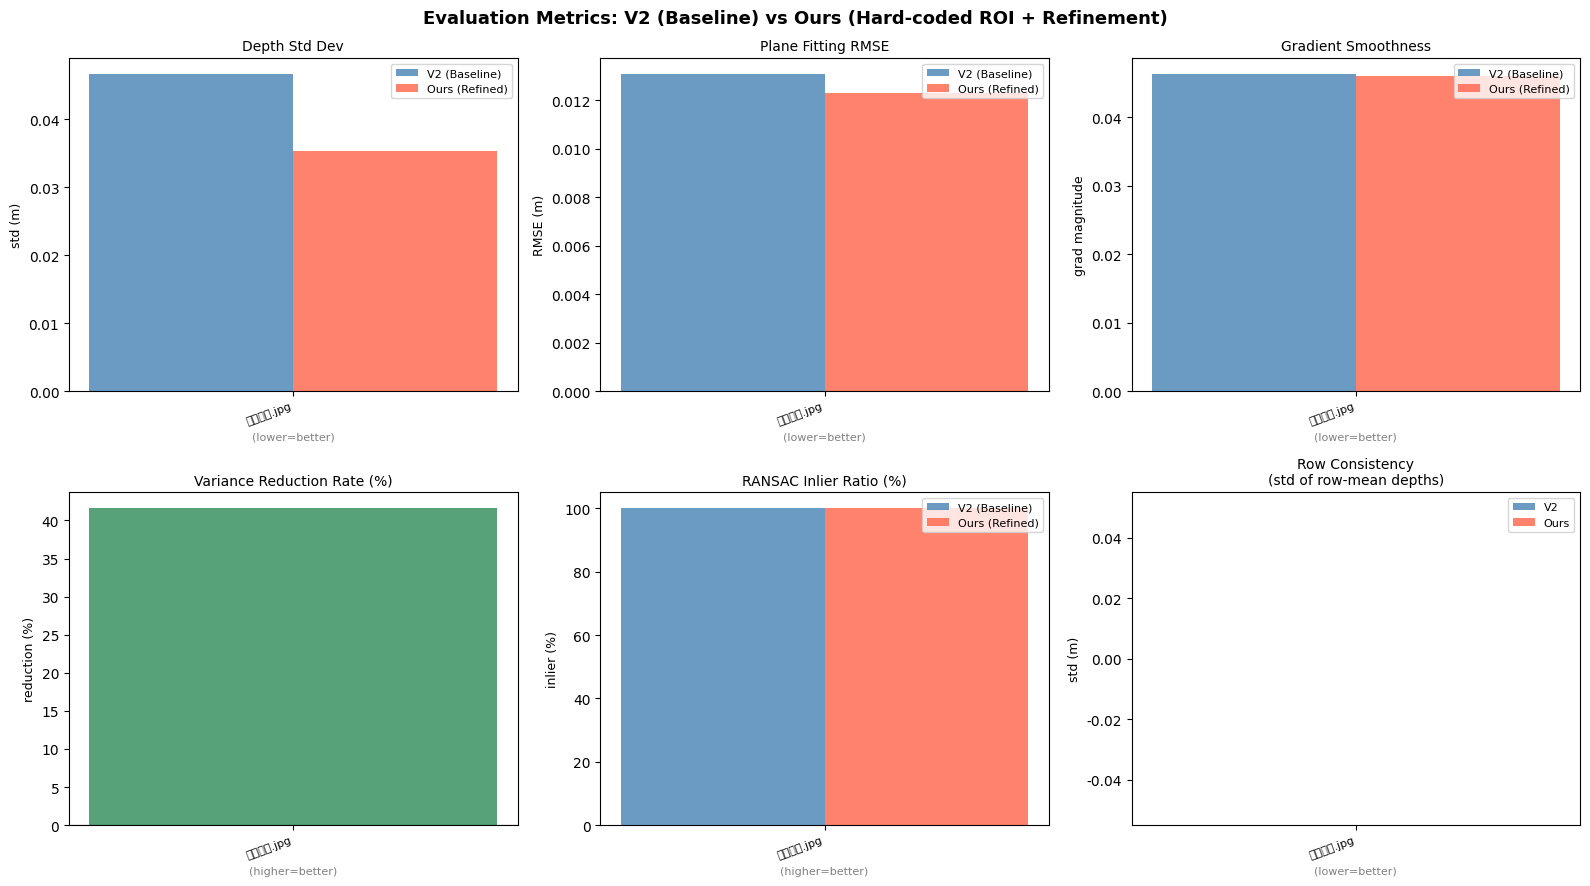

차트 저장: /content/metrics_chart.png


In [22]:
# [셀 7-4] 평가지표 바 차트

if all_stats_v4:
    df_all = pd.concat(all_stats_v4, ignore_index=True)
    df_g   = df_all.groupby('image').mean(numeric_only=True)
    imgs   = df_g.index.tolist()
    x      = np.arange(len(imgs))
    w      = 0.35

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(
        'Evaluation Metrics: V2 (Baseline) vs Ours (Hard-coded ROI + Refinement)',
        fontsize=13, fontweight='bold')

    def bar_pair(ax, col_v2, col_v4, title, ylabel, lower_better=True):
        ax.bar(x - w/2, df_g[col_v2], w, label='V2 (Baseline)',
               color='steelblue', alpha=0.8)
        ax.bar(x + w/2, df_g[col_v4], w, label='Ours (Refined)',
               color='tomato', alpha=0.8)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels(imgs, rotation=20, ha='right', fontsize=8)
        ax.legend(fontsize=8)
        note = '(lower=better)' if lower_better else '(higher=better)'
        ax.set_xlabel(note, fontsize=8, color='gray')

    bar_pair(axes[0,0], 'std_v2',         'std_v4',
             'Depth Std Dev',          'std (m)')
    bar_pair(axes[0,1], 'rmse_v2',        'rmse_v4',
             'Plane Fitting RMSE',     'RMSE (m)')
    bar_pair(axes[0,2], 'grad_smooth_v2', 'grad_smooth_v4',
             'Gradient Smoothness',    'grad magnitude')

    # 분산 감소율
    axes[1,0].bar(x, df_g['var_reduction_%'], color='seagreen', alpha=0.8)
    axes[1,0].axhline(0, color='black', linewidth=0.8)
    axes[1,0].set_title('Variance Reduction Rate (%)', fontsize=10)
    axes[1,0].set_ylabel('reduction (%)', fontsize=9)
    axes[1,0].set_xticks(x)
    axes[1,0].set_xticklabels(imgs, rotation=20, ha='right', fontsize=8)
    axes[1,0].set_xlabel('(higher=better)', fontsize=8, color='gray')

    bar_pair(axes[1,1], 'inlier_v2_%', 'inlier_v4_%',
             'RANSAC Inlier Ratio (%)', 'inlier (%)', lower_better=False)

    # 행 일관성
# 행 일관성 (None 값 처리 추가)
    if all_row_cons_v4:
        df_rc = pd.DataFrame(all_row_cons_v4).set_index('image')

        # None → 0으로 대체 (bar chart에서 None 못 씀)
        df_rc['row_consistency_v2'] = pd.to_numeric(
            df_rc['row_consistency_v2'], errors='coerce').fillna(0)
        df_rc['row_consistency_v4'] = pd.to_numeric(
            df_rc['row_consistency_v4'], errors='coerce').fillna(0)

        x_rc = np.arange(len(df_rc))
        axes[1,2].bar(x_rc - w/2, df_rc['row_consistency_v2'], w,
                      label='V2', color='steelblue', alpha=0.8)
        axes[1,2].bar(x_rc + w/2, df_rc['row_consistency_v4'], w,
                      label='Ours', color='tomato', alpha=0.8)
        axes[1,2].set_title('Row Consistency\n(std of row-mean depths)', fontsize=10)
        axes[1,2].set_ylabel('std (m)', fontsize=9)
        axes[1,2].set_xticks(x_rc)
        axes[1,2].set_xticklabels(df_rc.index, rotation=20, ha='right', fontsize=8)
        axes[1,2].legend(fontsize=8)
        axes[1,2].set_xlabel('(lower=better)', fontsize=8, color='gray')

    plt.tight_layout()
    plt.savefig('/content/metrics_chart.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('차트 저장: /content/metrics_chart.png')